In [2]:
import pandas as pd
from scipy.stats import chi2_contingency, f_oneway, kruskal
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load the data
hillstrom = pd.read_csv('data/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv')

hillstrom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


The documentation for the dataset can be found at [minthatdata analytics website](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html)

The dataset's columns:
    Recency: Months since last purchase.
    History_Segment: Categorization of dollars spent in the past year.
    History: Actual dollar value spent in the past year.
    Mens: 1/0 indicator, 1 = customer purchased Mens merchandise in the past year.
    Womens: 1/0 indicator, 1 = customer purchased Womens merchandise in the past year.
    Zip_Code: Classifies zip code as Urban, Suburban, or Rural.
    Newbie: 1/0 indicator, 1 = New customer in the past twelve months.
    Channel: Describes the channels the customer purchased from in the past year.

Another variable describes the e-mail campaign the customer received:

    Segment
        Mens E-Mail
        Womens E-Mail
        No E-Mail

Finally, we have a series of variables describing activity in the two weeks following delivery of the e-mail campaign:
    Visit: 1/0 indicator, 1 = Customer visited website in the following two weeks.
    Conversion: 1/0 indicator, 1 = Customer purchased merchandise in the following two weeks.
    Spend: Actual dollars spent in the following two weeks.

Customers were randomly split into 3 groups:
1. Men’s email arm: received an email featuring men’s merchandise
2. Women’s email arm: received an email featuring women’s merchandise
3. No email arm (control): received nothing

An A/B test has two arms (A and B). This one is an A/B/C test, so it has three. The control arm is the baseline you compare the others against.

In the data, the arm is stored in one column called segment. Each row is a customer, and that column tells you which group they were in.

In [4]:
# how many customers are in each arm
hillstrom['segment'].value_counts() # Just a slight variation but pretty much balanced.

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [5]:
# the outcome targets - spend and visit
hillstrom['visit'].value_counts(normalize=True) * 100


visit
0    85.321875
1    14.678125
Name: proportion, dtype: float64

In [6]:
hillstrom['spend'].describe()

# how many customers spent 0
spent_zero = hillstrom[hillstrom['spend']==0].count()

spent = hillstrom[hillstrom['spend'] > 0].count()

print('Spent nothing:',spent_zero['spend'])
print('Spent:', spent['spend'])

Spent nothing: 63422
Spent: 578


## Confirm randomization
The covariates (recency, history, channel, and the other columns) were measured before anyone got an email. So, if the assignments were truly random the 3 aem shouls look like the same kind of customers on every one of them.

To confirm this, I will create a table of means and proportions.

In [7]:
hillstrom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [8]:
# group by segment

# numerical columns
hillstrom.groupby('segment')[['recency', 'history']].agg(['mean', 'std', 'count'])

recency                      history                   
                   mean       std  count        mean         std  count
segment                                                                
Mens E-Mail    5.773642  3.513350  21307  242.835931  260.355685  21307
No E-Mail      5.749695  3.497517  21306  240.882653  252.739362  21306
Womens E-Mail  5.767850  3.511989  21387  242.536633  255.332880  21387

In [9]:
# share of each category by within each arm
pd.crosstab(hillstrom['segment'], hillstrom['newbie'])
pd.crosstab(hillstrom['segment'], hillstrom['channel'])
pd.crosstab(hillstrom['segment'], hillstrom['history_segment'])
pd.crosstab(hillstrom['segment'], hillstrom['zip_code'])
pd.crosstab(hillstrom['segment'], hillstrom['mens'])
pd.crosstab(hillstrom['segment'], hillstrom['womens'])

womens,0,1
segment,,
Mens E-Mail,9558,11749
No E-Mail,9638,11668
Womens E-Mail,9622,11765


The distribution seems similar looking at it but will use chi-square test to confirm that customer characteristics are similar across the 3 marketing groups.

$H_0$ There's no association between the customer's segment and their assignment marketing group
$H_1$ Theres an association between the customer's segment and their assignment marketing group.

if p_value > 0.05, we fail to reject the null hypothesis.

If there's a possible imbalance, I'll also use cramer's V to measure how strong the association is.
  | Cramér's V | Interpretation |
|---|---|
| 0 | No association |
| 0.1 | Weak association |
| 0.2 | Moderate association |
| 0.3 | Relatively strong association |
| 0.5 | Strong association |
| 1.0 | Perfect association |

In [10]:
categorical_features = [
    'newbie',
    'channel',
    'zip_code',
    'mens',
    'womens'
]

def cramers_v(contingency_table):
    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    return np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )
chi_results = []
for feature in categorical_features:

    # create contingency table
    contingency_table = pd.crosstab(
        hillstrom['segment'],
        hillstrom[feature]
    )

    # chi-square test
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    cramers_v_val = None
    if p_value < 0.05:
        # check strength of association
        cramers_v_val = cramers_v(contingency_table)        

    chi_results.append(
            {'feature': feature,
             'test': 'chi2',
            'statistic': chi2,
            'p_value': p_value,
            'outcome': (
                'No significant difference'
                if p_value > 0.05
                else 'Significant difference'
            ),

            'cramers_v_value': cramers_v_val
            }
        )
    
chi_results_df = pd.DataFrame(chi_results)
chi_results_df
# also measuring the strength of accociation using Cramer's V



,feature,test,statistic,p_value,outcome,cramers_v_value
0,newbie,chi2,0.136868,0.933855,No significant difference,None
1,channel,chi2,3.632402,0.458034,No significant difference,None
2,zip_code,chi2,2.871942,0.579479,No significant difference,None
3,mens,chi2,0.795994,0.671664,No significant difference,None
4,womens,chi2,0.632522,0.728869,No significant difference,None


Using ANOVA to check whether the means of the numerical features within the 3 groups are statistically different

$H_0$: The means are equal across all 3 groups
$H_1$: At-lease one groups average is different.

It calculates an f-statistic by comparing the variation between the group beans with the variation within each group.
* If the group means are close together relative to the variation within each group, the F-statistic will be small.
* If the group means are far apart relative to the variation within each group, the F-statistic will be large.

$F = \frac{\text{between-group variation}}{\text{within-group variation}}$

In [11]:
# Calculating anova
numerical_features = ['recency', 'history']

groups = hillstrom['segment'].unique()

results = []

for feature in numerical_features:

    samples = [hillstrom.loc[hillstrom['segment'] == group, feature].dropna() for group in groups]

    # one way anova
    f_stat, anova_p = f_oneway(*samples)
    results.append(
        {'feature': feature,
         'test': 'Anova',
        'statistic': f_stat,
        'p_value': anova_p,
        'outcome': (
            'No significant difference'
            if anova_p > 0.05
            else 'Significant difference'
        )
        }
    )

results_df = pd.DataFrame(results)
results_df

,feature,test,statistic,p_value,outcome
0,recency,Anova,0.270389,0.763083,No significant difference
1,history,Anova,0.359487,0.698036,No significant difference


No significant difference between the groups for numerical columns too.

In [12]:
balance_results = pd.concat(
    [chi_results_df, results_df],
    ignore_index=True
)

balance_results[['feature','p_value', 'outcome']]

,feature,p_value,outcome
0,newbie,0.933855,No significant difference
1,channel,0.458034,No significant difference
2,zip_code,0.579479,No significant difference
3,mens,0.671664,No significant difference
4,womens,0.728869,No significant difference
5,recency,0.763083,No significant difference
6,history,0.698036,No significant difference


In [ ]:
# visualizing with smd
hillstrom['treatment'] = (
    hillstrom['segment'] != 'No E-Mail'
).astype(int)


results = []

treatment = hillstrom[hillstrom['treatment'] == 1]
control = hillstrom[hillstrom['treatment'] == 0]

# Numerical features
for feature in numerical_features:
    mean_t = treatment[feature].mean()
    mean_c = control[feature].mean()

    pooled_sd = np.sqrt(
        (treatment[feature].var() + control[feature].var()) / 2
    )

    smd = (mean_t - mean_c) / pooled_sd

    results.append({'feature': feature, 'smd': abs(smd)})

# Categorical features
for feature in categorical_features:
    for category in hillstrom[feature].dropna().unique():
        p_t = (treatment[feature] == category).mean()
        p_c = (control[feature] == category).mean()

        pooled_sd = np.sqrt(
            (p_t * (1 - p_t) + p_c * (1 - p_c)) / 2
        )

        smd = (p_t - p_c) / pooled_sd if pooled_sd > 0 else 0

        results.append({
            'feature': f'{feature}: {category}',
            'smd': abs(smd)
        })

smd_df = pd.DataFrame(results)

smd_df # The closer the points are to zero, the more balanced the groups are.

,feature,smd
0,recency,0.006004
1,history,0.007063
2,newbie: 0,0.000836
3,newbie: 1,0.000836
4,channel: Phone,0.000194
5,channel: Web,0.002922
6,channel: Multichannel,0.004733
7,zip_code: Surburban,0.006405
8,zip_code: Rural,0.008811
9,zip_code: Urban,0.000102


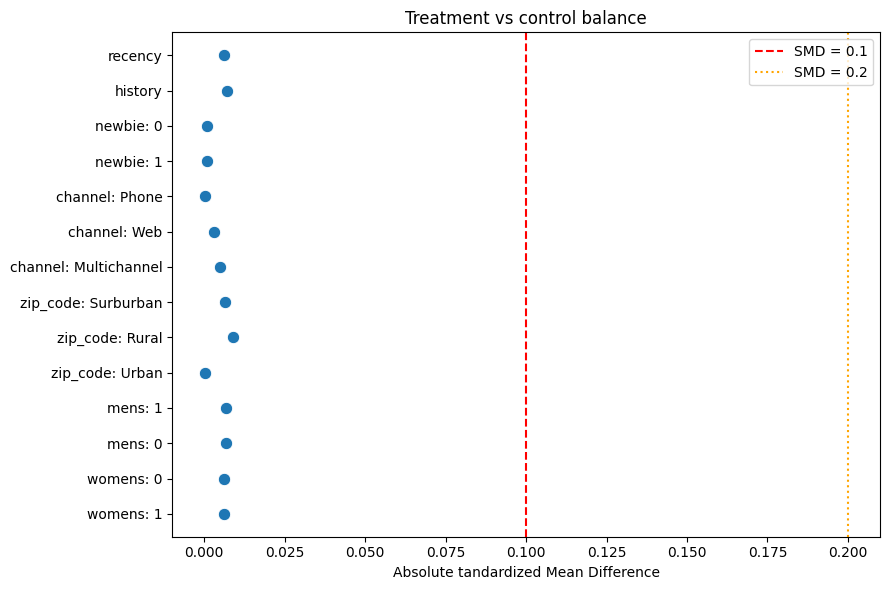

In [16]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=smd_df,
    x='smd',
    y='feature',
    s=80
)

plt.axvline(0.1, linestyle='--', color='red', label='SMD = 0.1')
plt.axvline(0.2, linestyle=':', color='orange', label='SMD = 0.2')

plt.xlabel('Absolute tandardized Mean Difference')
plt.ylabel('')
plt.title('Treatment vs control balance')
plt.legend()
plt.tight_layout()
plt.show()